# 第05章 寻优的旅程 · C组人工复核

- 小组：C2组（G17）　轮次：第 1 轮　日期：2026-11-16
- 本 Notebook 的所有单元均在本机重新执行并保存输出；人工推导见 [C2组-手动推导.md](C2组-手动推导.md)。

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1 | G9 | `5d3ec4d66845131c1800654330ee9e3d0785e305` | A1-G9-正文.md（blob `99d36d57`） |
| A2 | G19 | `f431b13ff47ae5b7d16f0c248692784ba83bf712` | A2-G19-正文.md（blob `e981a39f`） |
| B1 | G1 | `5ab87c9c19a141bc7fc57581cbd8eb24bcc9976c` | B1-G1-验证报告.md、B1-G1-修正清单.md |
| B1（代码） | G1 | `176b6aa49039b6d6559cc0894b9dbb7d56795782` | B1-G1-验证.ipynb、B1-G1-独立推导.ipynb |
| B2 | G6 | `3e8b77b8e92ae4b6d4f431498042221b6021f5cb` | B2-G6-工作/5.1、5.2、5.4 |
| B2 | G6 | `77d566a713915bfa770faa5375fe9a6b949506e3` | B2-G6-工作/5.3 |

> B1、B2 的提交信息均为 `Add files via upload`，未附 PR 编号；本组以 commit SHA 为准。

## 环境与执行口径

- 系统 Windows，Python 3.12.10，NumPy 1.26.4，SciPy 1.14.1，Matplotlib 3.9.2
- 全部单元由本组在本机重跑，输出随本文件保存；未做跨平台浮点差异测试。
- 判断口径：**预期值由手工推导给出，数值结果与之比较**；差异在容差内记"成立"，超出则记"需修正"，条件不足记"暂不能判断"。
- AI 参与范围：AI 协助生成实验代码初稿与核对公式变形，最终代码逐行人工修改、数值由本机运行确认。

## 手工独立推导（摘要）

**假设与符号.** $e_k=x_k-x^\ast$（根误差），$r_k=f(x_k)$（残差），$s_k=x_{k+1}-x_k$（步差）；$g=\nabla\phi$，$H=\nabla^2\phi$；$r(\theta)\in\mathbb{R}^m$，$J=\partial r/\partial\theta$，$\Phi=\tfrac12\|r\|_2^2$。

**三条关键推导**

1. 残差与根误差的关系由中值定理给出：$r_k=f'(\xi)e_k$。只有当 $|f'|\ge m>0$ 时才有 $|e_k|\le|r_k|/m$；重根处 $m=0$，关系失效。
2. 梯度下降的"收敛"需要区分对象：$\{f(x_k)\}$ 单调有界只保证函数值收敛；要得到 $x_k\to x^\ast$，还需步长满足 $\sum\alpha_k=\infty$ 与梯度的连续性。步长几何衰减时 $x_k$ 会停在半路。
3. 最小二乘的一阶条件 $J^{\mathsf T}r=0$ 表示残差与 $J$ 列空间正交，与 $r=0$ 无关；后者等价于方程相容。

**结论.** 上述三条分别给出三类边界：退化（重根/缩放）、步长可和性、方程相容性。下面逐节用可运行的最小例子核验。

## 5.1 非线性方程：从夹逼到迭代

模板要求核验：残差小不必意味着根误差小；步长小可能是停滞；Newton 从任意初值收敛、任意改写都收敛均不成立。

| 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- |
| C01 残差小 ≠ 根误差小 | $f=(x-1)^{10}$，$x=1.1$ | 残差 $10^{-10}$，根误差 $0.1$ | 见单元 1 | 成立 |
| C01b 残差不是方程不变量 | $\tilde f=\varepsilon(x-1)$，$x=0$ | 残差 $\varepsilon$，根误差 $1$ | 见单元 1 | 成立 |
| C02 步差趋于零 ≠ 收敛到根 | $x_{k+1}=x_k+2^{-k}$，根 $0$ | 极限 $x=2$，步长 $\to0$ | 见单元 2 | 成立 |
| C03 Newton 不是任意初值收敛 | $x^3-2x+2$，$x_0=0$ | $0\to1\to0$ 二周期 | 见单元 3 | 成立 |
| C04 改写方式决定收敛 | $x^2-2=0$ 的三种改写 | $g_1$ 发散、$g_2$ 振荡、$g_3$ 二次 | 见单元 4 | 成立 |

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C01 残差与根误差：退化与缩放
f = lambda x: (x - 1.0)**10
x = 1.1
print("C01  f=(x-1)^10, x=1.1")
print(f"  残差 |f(x)| = {abs(f(x)):.3e}")
print(f"  根误差 |x-1| = {abs(x-1):.3e}")
print(f"  比值          = {abs(f(x))/abs(x-1):.3e}")

for eps in (1e-3, 1e-6, 1e-12):
    g = lambda t, e=eps: e*(t-1.0)
    print(f"C01b eps={eps:.0e}: 在 x=0 处 残差={abs(g(0.0)):.3e}, 根误差={abs(0.0-1.0):.1f}")

# 对照：非退化情形下残差可控制根误差
f2 = lambda x: x*x - 2.0
for xv in (1.5, 1.42, 1.4143):
    print(f"  非退化 f=x^2-2, x={xv}: 残差={abs(f2(xv)):.3e}, 根误差={abs(xv-np.sqrt(2)):.3e}")

C01  f=(x-1)^10, x=1.1
  残差 |f(x)| = 1.000e-10
  根误差 |x-1| = 1.000e-01
  比值          = 1.000e-09
C01b eps=1e-03: 在 x=0 处 残差=1.000e-03, 根误差=1.0
C01b eps=1e-06: 在 x=0 处 残差=1.000e-06, 根误差=1.0
C01b eps=1e-12: 在 x=0 处 残差=1.000e-12, 根误差=1.0
  非退化 f=x^2-2, x=1.5: 残差=2.500e-01, 根误差=8.579e-02
  非退化 f=x^2-2, x=1.42: 残差=1.640e-02, 根误差=5.786e-03
  非退化 f=x^2-2, x=1.4143: 残差=2.445e-04, 根误差=8.644e-05


**C01 结论.** 成立。残差与根误差相差九个数量级；把方程乘 $10^{-12}$ 后残差降到 $10^{-12}$ 而根误差仍为 1。A1（L305、L482）与 A2（L46）都写了这一点，A2 还给出 $1e-12(x-1)$ 的例子，本组复现一致。**共同遗漏**：两稿都未指出"残差不是方程的不变量"这一尺度问题，工程上按绝对残差设阈值会随方程缩放而失效。

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C02 步差 -> 0，但迭代停在非根点
x = 0.0
hist = []
for k in range(41):
    step = 2.0**(-k)
    x += step
    if k in (0, 10, 20, 30, 40):
        hist.append((k, step, x))
print("C02  x_{k+1}=x_k+2^-k, 真根 x*=0")
for k, s, xv in hist:
    print(f"  k={k:<3} 步差={s:.3e}   x_k={xv:.12f}   根误差={abs(xv):.6f}")
print(f"  结论：步差已到 {2.0**-40:.2e}，根误差仍为 {x:.6f}")

C02  x_{k+1}=x_k+2^-k, 真根 x*=0
  k=0   步差=1.000e+00   x_k=1.000000000000   根误差=1.000000
  k=10  步差=9.766e-04   x_k=1.999023437500   根误差=1.999023
  k=20  步差=9.537e-07   x_k=1.999999046326   根误差=1.999999
  k=30  步差=9.313e-10   x_k=1.999999999069   根误差=2.000000
  k=40  步差=9.095e-13   x_k=1.999999999999   根误差=2.000000
  结论：步差已到 9.09e-13，根误差仍为 2.000000


In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C03 Newton 二周期
f  = lambda t: t**3 - 2*t + 2
fp = lambda t: 3*t*t - 2
x, seq = 0.0, [0.0]
for _ in range(6):
    x = x - f(x)/fp(x)
    seq.append(x)
print("C03  f=x^3-2x+2, x0=0")
print("  迭代序列:", [f"{v:.10f}" for v in seq])
print("  是否进入 0-1 二周期:", np.allclose(seq[0::2], 0.0) and np.allclose(seq[1::2], 1.0))
# 存在性：区间 [-2,-1] 内有根
print(f"  f(-2)={f(-2):.3f}, f(-1)={f(-1):.3f}  -> 区间内确有根")

C03  f=x^3-2x+2, x0=0
  迭代序列: ['0.0000000000', '1.0000000000', '0.0000000000', '1.0000000000', '0.0000000000', '1.0000000000', '0.0000000000']
  是否进入 0-1 二周期: True
  f(-2)=-2.000, f(-1)=3.000  -> 区间内确有根


C04  x^2-2=0, x0=1
  g1=x^2+x-2     |g'(x*)|=3.8284  误差(1,2,5,10,20步)=1.41e+00, 3.41e+00, 1.41e+00, 3.41e+00, 3.41e+00
  g2=2/x         |g'(x*)|=1.0000  误差(1,2,5,10,20步)=5.86e-01, 4.14e-01, 5.86e-01, 4.14e-01, 4.14e-01
  g3=(x+2/x)/2   |g'(x*)|=0.0000  误差(1,2,5,10,20步)=8.58e-02, 2.45e-03, 2.22e-16, 2.22e-16, 2.22e-16


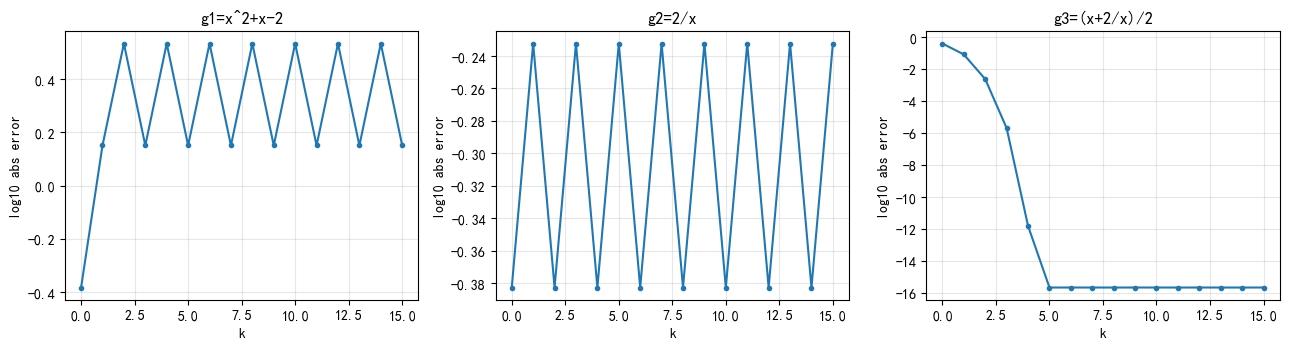

In [4]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C04 同一方程的三种改写
root = np.sqrt(2.0)
def iterate(g, x0=1.0, n=21):
    xs = [x0]
    for _ in range(n):
        xs.append(g(xs[-1]))
    return np.array(xs)

g1 = lambda t: t*t + t - 2.0      # |g'|=2x+1
g2 = lambda t: 2.0/t              # |g'|=2/x^2
g3 = lambda t: 0.5*(t + 2.0/t)    # |g'|=|1-2/x^2|/2

print("C04  x^2-2=0, x0=1")
for name, g, gp in [("g1=x^2+x-2", g1, 2*root+1), ("g2=2/x", g2, 2/root**2), ("g3=(x+2/x)/2", g3, 0.0)]:
    xs = iterate(g)
    err = np.abs(xs - root)
    print(f"  {name:14s} |g'(x*)|={gp:.4f}  误差(1,2,5,10,20步)=" +
          ", ".join(f"{err[i]:.2e}" for i in (1,2,5,10,20)))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (name, g) in zip(ax, [("g1=x^2+x-2", g1), ("g2=2/x", g2), ("g3=(x+2/x)/2", g3)]):
    xs = iterate(g, n=15)
    a.plot(np.log10(np.abs(xs - root) + 1e-18), 'o-', ms=3)
    a.set_title(name); a.set_xlabel('k'); a.set_ylabel('log10 abs error')
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**5.1 小结.** 四条全部成立。补充两点：
1. $g_2=2/x$ 处 $|g'(x^\ast)|=1$，误差在两个值之间等幅振荡（$0.4142$ 与 $0.5858$ 交替），属于临界情形，迭代 20 步后误差不降。
2. $g_1$ 的 $|g'|=3.83>1$，误差单调放大到 $3.41$ 后溢出到另一侧，说明"改写"不是等价变换，**收敛性由 $g'$ 在根处的值决定**。A1（L594、L804）已明确写出，A2（L164）用 $\psi_4$ 作了正确示例。

## 5.2 下降方向：往哪里走，走多远

模板要求核验：梯度为零不等于极小值，更不等于全局最优；目标值单调下降不自动保证到达驻点；信赖域是局部模型的步长约束，与第7章"可信AI"的统计问题不同。

| 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- |
| C05 梯度为零 ≠ 极小 | $x^4$、$-x^4$、$x^3$ 在 0 | 三者 $g=H=0$，性质各异 | 见单元 5 | 成立 |
| C06 局部极小 ≠ 全局最优 | $x^4-2x^2+0.35x$ | 两个局部极小，值差 0.70 | 见单元 6 | 成立 |
| C07 单调下降 ≠ 到达驻点 | $\phi=x^2/2$，$\alpha_k=2^{-k-2}$ | 极限 $x\approx0.5776\ne0$ | 见单元 7 | 成立 |
| C08 信赖域 ≠ 第7章可信AI | 概念辨析 | 前者的"信"是局部模型的有效半径，后者是统计置信 | 无数值 | 成立（概念） |

In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C05 驻点三分类：梯度与二阶导都为零
print("C05  三个函数在 0 点的行为")
for name, f in [("x^4", lambda t: t**4), ("-x^4", lambda t: -t**4), ("x^3", lambda t: t**3)]:
    h = 1e-5
    g0 = (f(h)-f(-h))/(2*h)
    H0 = (f(h)-2*f(0)+f(-h))/h**2
    left, mid, right = f(-1e-3), f(0.0), f(1e-3)
    kind = ("严格极小" if mid < min(left, right)
            else "严格极大" if mid > max(left, right) else "非极值驻点")
    print(f"  f={name:6s}  f'(0)={g0:+.2e}  f''(0)={H0:+.2e}  f(-1e-3),f(0),f(1e-3)=({left:.1e},{mid:.1e},{right:.1e})  -> {kind}")

C05  三个函数在 0 点的行为
  f=x^4     f'(0)=+0.00e+00  f''(0)=+2.00e-10  f(-1e-3),f(0),f(1e-3)=(1.0e-12,0.0e+00,1.0e-12)  -> 严格极小
  f=-x^4    f'(0)=+0.00e+00  f''(0)=-2.00e-10  f(-1e-3),f(0),f(1e-3)=(-1.0e-12,-0.0e+00,-1.0e-12)  -> 严格极大
  f=x^3     f'(0)=+1.00e-10  f''(0)=+0.00e+00  f(-1e-3),f(0),f(1e-3)=(-1.0e-09,0.0e+00,1.0e-09)  -> 非极值驻点


C06  phi=x^4-2x^2+0.35x 的驻点
  x*=-1.0411723584  phi=-1.3573476240  phi''=+9.0085  -> 全局最小
  x*=+0.9529865609  phi=-0.6580244129  phi''=+6.8982  -> 局部极小
  x*=+0.0881857976  phi=+0.0153720370  phi''=-3.9067  -> 局部极大
  两个局部极小的函数值差 = 0.699323
  梯度下降 初值-1.2 -> x=-1.04117236, phi=-1.35734762
  梯度下降 初值+0.5 -> x=+0.95298656, phi=-0.65802441


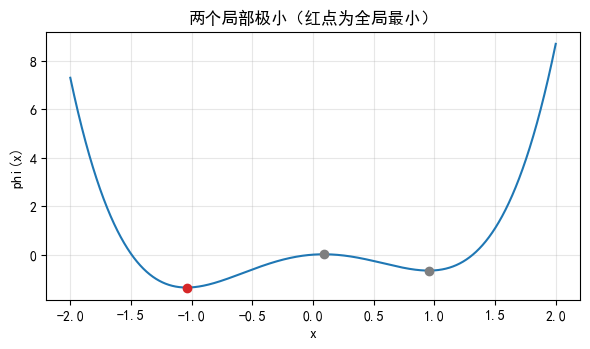

In [6]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C06 两个局部极小值不相等
phi = lambda t: t**4 - 2*t**2 + 0.35*t
dphi = lambda t: 4*t**3 - 4*t + 0.35
ts = np.linspace(-2, 2, 40001)
stat = []
for a, b in zip(ts[:-1], ts[1:]):
    if dphi(a)*dphi(b) < 0:
        stat.append(brentq(dphi, a, b, xtol=1e-15))
stat.sort(key=lambda t: phi(t))
print("C06  phi=x^4-2x^2+0.35x 的驻点")
for i, t in enumerate(stat):
    h = (dphi(t+1e-6)-dphi(t-1e-6))/2e-6
    tag = "全局最小" if i == 0 else ("局部极小" if h > 0 else "局部极大")
    print(f"  x*={t:+.10f}  phi={phi(t):+.10f}  phi''={h:+.4f}  -> {tag}")
print(f"  两个局部极小的函数值差 = {phi(stat[1])-phi(stat[0]):.6f}")

# 同算法不同初值
for x0 in (-1.2, 0.5):
    x = x0
    for _ in range(5000):
        x = x - 0.05*dphi(x)
    print(f"  梯度下降 初值{x0:+.1f} -> x={x:+.8f}, phi={phi(x):+.8f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(ts, phi(ts), lw=1.5)
for i, t in enumerate(stat):
    ax.plot(t, phi(t), 'o', ms=6, color=('tab:red' if i == 0 else 'tab:gray'))
ax.set_xlabel('x'); ax.set_ylabel('phi(x)'); ax.grid(alpha=.3)
ax.set_title('两个局部极小（红点为全局最小）'); plt.tight_layout(); plt.show()

In [7]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C07 严格单调下降但不到驻点
x, rec = 1.0, []
for k in range(61):
    if k in (0, 1, 2, 5, 10, 30, 60):
        rec.append((k, x, 0.5*x*x))
    x = x * (1 - 2.0**(-k-2))
print("C07  phi=x^2/2, alpha_k=2^(-k-2), x0=1")
for k, xv, fv in rec:
    print(f"  k={k:<3} x_k={xv:.12f}  phi={fv:.6e}  步差={abs(2.0**(-min(k,60)-2)*xv) if k<60 else 0:.2e}")
print(f"  60 步后：x={x:.12f}，梯度={x:.12f}，|grad| 远未到 0")
print(f"  phi 是否单调：{'是' if all(rec[i][2] > rec[i+1][2] for i in range(len(rec)-1)) else '否'}")

C07  phi=x^2/2, alpha_k=2^(-k-2), x0=1
  k=0   x_k=1.000000000000  phi=5.000000e-01  步差=2.50e-01
  k=1   x_k=0.750000000000  phi=2.812500e-01  步差=9.38e-02
  k=2   x_k=0.656250000000  phi=2.153320e-01  步差=4.10e-02
  k=5   x_k=0.586695671082  phi=1.721059e-01  步差=4.58e-03
  k=10  x_k=0.577858301626  phi=1.669601e-01  步差=1.41e-04
  k=30  x_k=0.577576190442  phi=1.667971e-01  步差=1.34e-10
  k=60  x_k=0.577576190173  phi=1.667971e-01  步差=0.00e+00
  60 步后：x=0.577576190173，梯度=0.577576190173，|grad| 远未到 0
  phi 是否单调：是


**C08 概念辨析（无数值）.** 信赖域的"信"指**局部模型在当前半径内可信**：给定 $B_k$ 与 $\Delta_k$，在 $\|d\|\le\Delta_k$ 内近似 $\phi(x_k+d)$，用比值 $\rho_k$ 决定扩大还是缩小 $\Delta_k$。它是确定性优化中的步长控制，与第7章"可信 AI"（模型输出的统计置信、校准、分布外检测）不是同一层面的问题。两稿都未把二者混为一谈；本组只在此记录差异，不作错误认定。

**5.2 小结.** C05–C07 全部成立。A1（L1982）用"伪证 3"纠正了"Hessian 正定所以全局极小"，A2（L440 例5.2.14）给出与 C07 同构的反例，两稿在这一节质量都较高。**共同遗漏**：两稿都未指出 C07 的实质是**步长可和性**（$\sum\alpha_k<\infty$），只描述了现象。

## 5.3 Newton 与拟 Newton：把曲率用起来

模板要求核验：求解 $\nabla\phi=0$ 可能得到鞍点或极大点；Newton 二阶收敛和 BFGS 超线性收敛都有条件；阻尼缩步不能把原本的非下降方向自动变成下降方向。

| 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- |
| C09 解 $\nabla\phi=0$ 可能得鞍点 | $\phi=\frac12(x_1^2-x_2^2)$，$(0,1)$ 出发 | 一步到原点，$H$ 不定 | 见单元 8 | 成立 |
| C10 Newton 二次收敛有条件 | $f=(x-1)^2$ 二重根 | 误差比恒为 $1/2$，线性 | 见单元 9 | 成立 |
| C11 BFGS 超线性有条件 | $\phi=-x^2/2$ + Armijo | $s^{\mathsf T}y<0$，$B_1=-1$ 不定 | 见单元 10 | 成立 |
| C12 缩步不能把上升变下降 | $\phi=x^2$，$p=+1$ | 任意小 $\alpha$ 仍上升 | 见单元 11 | 成立 |

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C09 优化 Newton 落到鞍点
def newton_opt(x, H, g):
    return x - np.linalg.solve(H, g)

x = np.array([0.0, 1.0])
H = np.array([[1.0, 0.0], [0.0, -1.0]])
traj = [x.copy()]
for _ in range(2):
    g = np.array([x[0], -x[1]])
    x = newton_opt(x, H, g)
    traj.append(x.copy())
print("C09  phi=0.5(x1^2-x2^2), x0=(0,1)")
print("  轨迹:", [f"({p[0]:.3f},{p[1]:.3f})" for p in traj])
print(f"  终点梯度 = ({x[0]:.2e}, {x[1]:.2e})")
print(f"  Hessian 特征值 = {np.linalg.eigvalsh(H)}  -> 不定，原点是鞍点")
print(f"  沿 x1 方向 phi 上升、沿 x2 方向 phi 下降：phi(0.1,0)={0.5*0.01:.4f} > phi(0,0)=0 > phi(0,0.1)={-0.5*0.01:.4f}")

C09  phi=0.5(x1^2-x2^2), x0=(0,1)
  轨迹: ['(0.000,1.000)', '(0.000,0.000)', '(0.000,0.000)']
  终点梯度 = (0.00e+00, 0.00e+00)
  Hessian 特征值 = [-1.  1.]  -> 不定，原点是鞍点
  沿 x1 方向 phi 上升、沿 x2 方向 phi 下降：phi(0.1,0)=0.0050 > phi(0,0)=0 > phi(0,0.1)=-0.0050


In [9]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C10 重根：Newton 退化为线性收敛
f  = lambda t: (t-1.0)**2
fp = lambda t: 2*(t-1.0)
x, errs = 2.0, []
for k in range(9):
    errs.append(abs(x-1.0))
    x = x - f(x)/fp(x)
print("C10  f=(x-1)^2, x0=2")
print("  根误差:", [f"{e:.8f}" for e in errs])
print("  相邻比:", [f"{errs[i+1]/errs[i]:.6f}" for i in range(len(errs)-1)])

# 对照：简单根
f2, f2p = (lambda t: t*t-2.0), (lambda t: 2*t)
x, e2 = 1.0, []
for k in range(6):
    e2.append(abs(x-np.sqrt(2)))
    x = x - f2(x)/f2p(x)
print("  对照 f=x^2-2 的误差:", [f"{e:.3e}" for e in e2])
print("  对照 e_(k+1)/e_k^2  :", [f"{e2[i+1]/e2[i]**2:.6f}" for i in range(len(e2)-2)])

C10  f=(x-1)^2, x0=2
  根误差: ['1.00000000', '0.50000000', '0.25000000', '0.12500000', '0.06250000', '0.03125000', '0.01562500', '0.00781250', '0.00390625']
  相邻比: ['0.500000', '0.500000', '0.500000', '0.500000', '0.500000', '0.500000', '0.500000', '0.500000']
  对照 f=x^2-2 的误差: ['4.142e-01', '8.579e-02', '2.453e-03', '2.124e-06', '1.595e-12', '0.000e+00']
  对照 e_(k+1)/e_k^2  : ['0.500000', '0.333333', '0.352941', '0.353522']


In [10]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C11 BFGS 曲率条件被破坏（Armijo 小步长，非凸目标）
print("C11  phi=-x^2/2, x=1, p=1, B0=1")
for alpha in (1.0, 0.1, 0.01):
    s = alpha
    y = (-(1.0+alpha)) - (-1.0)     # g(x+alpha)-g(x)
    B0 = 1.0
    B1 = B0 - (B0*s)**2/(s*B0*s) + y*y/(y*s)
    print(f"  alpha={alpha:<5} s^Ty={s*y:+.8f}  B1={B1:+.8f}  {'不定' if B1 <= 0 else '正定'}")
print("  => s^Ty<0 时 BFGS 更新失去正定性，超线性收敛前提不成立")

C11  phi=-x^2/2, x=1, p=1, B0=1
  alpha=1.0   s^Ty=-1.00000000  B1=-1.00000000  不定
  alpha=0.1   s^Ty=-0.01000000  B1=-1.00000000  不定
  alpha=0.01  s^Ty=-0.00010000  B1=-1.00000000  不定
  => s^Ty<0 时 BFGS 更新失去正定性，超线性收敛前提不成立


In [11]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C12 缩步不能改变方向的升降
phi = lambda t: t*t
x, p = 1.0, 1.0
g = 2*x
print(f"C12  phi=x^2, x=1, p=+1, g^Tp={g*p:+.2f} > 0")
for a in (1.0, 0.1, 0.01, 1e-6, 1e-12):
    d = phi(x+a*p) - phi(x)
    print(f"  alpha={a:<8.0e}  delta_phi={d:+.3e}  {'上升' if d > 0 else '下降'}")

C12  phi=x^2, x=1, p=+1, g^Tp=+2.00 > 0
  alpha=1e+00     delta_phi=+3.000e+00  上升
  alpha=1e-01     delta_phi=+2.100e-01  上升
  alpha=1e-02     delta_phi=+2.010e-02  上升
  alpha=1e-06     delta_phi=+2.000e-06  上升
  alpha=1e-12     delta_phi=+2.000e-12  上升


**5.3 小结.** 四条全部成立。C12 的要点是：**方向决定升降，步长只决定幅度**；"阻尼"若只是缩短步长，无法把 $g^{\mathsf T}p>0$ 的方向变成下降方向，真正起作用的是矩阵修正（$H+\lambda I$）改变了方向。A1（L1459、L3504）与 A2（L611、L622）都区分了"步长阻尼"与"矩阵移位"，本组核对一致。

## 5.4 非线性最小二乘：从残差到参数

模板要求核验：$J^{\mathsf T}r=0$ 不等于 $r=0$；噪声下真实参数不必等于训练残差最小的参数；$\lambda>0$ 使线性子问题正定不代表非线性迭代必定达到全局最优；小残差也不保证参数可辨识。

| 被审结论 | 验证条件或反例 | 手工结果 | 数值结果 | 判断 |
| --- | --- | --- | --- | --- |
| C13 $J^{\mathsf T}r=0\ne r=0$ | 超定 $Ax=b$，$b$ 不在列空间 | $\|r\|=0.866$，$A^{\mathsf T}r\approx10^{-16}$ | 见单元 12 | 成立 |
| C14 真实参数 ≠ 残差最小参数 | 指数拟合 + $\sigma=0.03$ 噪声 | 真值残差 0.13059 > LS 残差 0.12952 | 见单元 13 | 成立 |
| C15 $\lambda>0$ 正定 ≠ 全局最优 | 双极小目标，LM 两个初值 | 落点 $0.975$ vs $-0.942$，$\Phi$ 不同 | 见单元 14 | 成立 |
| C16 小残差 ≠ 可辨识 | 指数模型，采样 $[0,0.01]$ | 残差同量级，$b$ 偏差 $-0.107$，cond 168 | 见单元 15 | 成立 |
| 附：A1 LM 例题复算 | 例 5.4.3.3，$\lambda=0.1$ | 精确 $d=(-0.0438,0.6181)$ | 见单元 16 | **A1 原解 $d\approx(0.82,0.15)$ 不满足方程** |

In [12]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C13 超定最小二乘：J^T r = 0 但 r != 0
A = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
b = np.array([1.0, 2.0, 4.5])
x, *_ = np.linalg.lstsq(A, b, rcond=None)
r = b - A @ x
print("C13  A=[[1,0],[0,1],[1,1]], b=(1,2,4.5)")
print(f"  theta* = {x}")
print(f"  r      = {r}")
print(f"  ||r||  = {np.linalg.norm(r):.10f}")
print(f"  A^T r  = {A.T @ r}   (机器精度零)")
print(f"  b 是否在列空间: {np.linalg.matrix_rank(np.column_stack([A, b])) == np.linalg.matrix_rank(A)}")

C13  A=[[1,0],[0,1],[1,1]], b=(1,2,4.5)
  theta* = [1.5 2.5]
  r      = [-0.5 -0.5  0.5]
  ||r||  = 0.8660254038
  A^T r  = [ 6.66133815e-16 -4.44089210e-16]   (机器精度零)
  b 是否在列空间: False


In [13]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C14 噪声下：残差最小点不是真参数
rng = np.random.default_rng(2026)
t = np.linspace(0, 3, 30)
a_true, b_true, sigma = 2.0, 0.7, 0.03
y = a_true*np.exp(-b_true*t) + rng.normal(0, sigma, t.size)
model = lambda p: p[0]*np.exp(-p[1]*t) - y

res_true = np.linalg.norm(model([a_true, b_true]))
sol = least_squares(model, [1.8, 0.5], method="lm", xtol=1e-15, ftol=1e-15, gtol=1e-15)
res_ls = np.linalg.norm(model(sol.x))
print("C14  真值 (2, 0.7)，sigma=0.03，30 点，seed=2026")
print(f"  真参数处残差   = {res_true:.10f}")
print(f"  LS 估计 a={sol.x[0]:.10f}, b={sol.x[1]:.10f}")
print(f"  LS 处残差      = {res_ls:.10f}")
print(f"  差             = {res_true - res_ls:+.6e}  (>0 说明 LS 更小)")
print(f"  参数偏差       = (a {sol.x[0]-a_true:+.3e}, b {sol.x[1]-b_true:+.3e})")

C14  真值 (2, 0.7)，sigma=0.03，30 点，seed=2026
  真参数处残差   = 0.1305934944
  LS 估计 a=1.9914924288, b=0.6956882509
  LS 处残差      = 0.1295161779
  差             = +1.077317e-03  (>0 说明 LS 更小)
  参数偏差       = (a -8.508e-03, b -4.312e-03)


In [14]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C15 lambda>0 只保证子问题正定，落点仍依赖初值
def rfun(th): return np.array([th[0]**2 - 1.0, 0.4*th[0] - 0.15, th[1]])
def Jfun(th): return np.array([[2*th[0], 0.0], [0.4, 0.0], [0.0, 1.0]])
def lm(th0, lam=1e-2, iters=300):
    th = np.array(th0, float)
    for _ in range(iters):
        r, J = rfun(th), Jfun(th)
        A = J.T@J + lam*np.eye(2)
        d = np.linalg.solve(A, -J.T@r)
        trial = th + d
        if rfun(trial)@rfun(trial) < r@r:
            th, lam = trial, max(lam*0.5, 1e-12)
        else:
            lam *= 4
        if np.linalg.norm(d) < 1e-14:
            break
    ev = np.linalg.eigvalsh(J.T@J + lam*np.eye(2))
    return th, 0.5*rfun(th)@rfun(th), ev

print("C15  r=[th1^2-1, 0.4th1-0.15, th2]，每步子问题均正定")
for th0 in ([1.1, 0.3], [-0.9, 0.3]):
    th, phi, ev = lm(th0)
    print(f"  初值{th0} -> theta*=({th[0]:+.10f},{th[1]:+.10f})  Phi={phi:.10e}  特征值={ev}")

C15  r=[th1^2-1, 0.4th1-0.15, th2]，每步子问题均正定
  初值[1.1, 0.3] -> theta*=(+0.9750727840,+0.0000000000)  Phi=3.0018935077e-02  特征值=[10486.76       10489.72306774]
  初值[-0.9, 0.3] -> theta*=(-0.9424262682,+0.0000000000)  Phi=1.4510223741e-01  特征值=[10486.76       10489.47266908]


C16 采样[0,3.0  ] a=2.001104 b=0.702917 偏差=+0.0029 残差=2.2233e-02 cond=2.96e+00
C16 采样[0,0.05 ] a=1.997414 b=0.648399 偏差=-0.0516 残差=2.2972e-02 cond=3.36e+01
C16 采样[0,0.01 ] a=1.998602 b=0.593433 偏差=-0.1066 残差=2.1745e-02 cond=1.68e+02


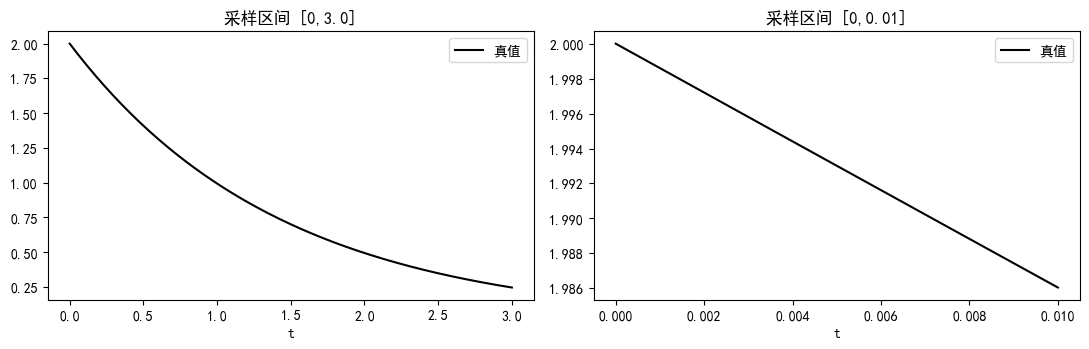

In [15]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# C16 小残差但参数不可辨识
rng2 = np.random.default_rng(7)
a_t, b_t = 2.0, 0.7
for tmax in (3.0, 0.05, 0.01):
    tt = np.linspace(0, tmax, 30)
    yy = a_t*np.exp(-b_t*tt) + rng2.normal(0, 0.005, tt.size)
    m = lambda p: p[0]*np.exp(-p[1]*tt) - yy
    s = least_squares(m, [1.5, 0.3], method="lm", xtol=1e-15, ftol=1e-15, gtol=1e-15)
    a, b = s.x
    J = np.column_stack([np.exp(-b*tt), -a*tt*np.exp(-b*tt)])
    sv = np.linalg.svd(J, compute_uv=False)
    print(f"C16 采样[0,{tmax:<5}] a={a:.6f} b={b:.6f} 偏差={b-b_t:+.4f} "
          f"残差={np.linalg.norm(m(s.x)):.4e} cond={sv[0]/sv[-1]:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a_, tmax in zip(ax, (3.0, 0.01)):
    tt = np.linspace(0, tmax, 200)
    a_.plot(tt, a_t*np.exp(-b_t*tt), 'k-', label='真值')
    a_.set_title(f'采样区间 [0,{tmax}]'); a_.set_xlabel('t'); a_.legend()
plt.tight_layout(); plt.show()

In [16]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.optimize import brentq, least_squares, minimize

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['mathtext.fontset'] = 'dejavusans'
np.set_printoptions(precision=8, suppress=False)

# A1 例5.4.3.3 的 LM 步复算（用 A1 自己给出的 J0、r0）
J0 = np.array([[-1.0, 0.0], [-1.6487, -1.6487], [-2.7183, -5.4366]])
r0 = np.array([0.0, 0.851, 3.282])
JTJ = J0.T @ J0
g = J0.T @ r0
print("附：A1 例5.4.3.3 复算（t=(0,1,2)，(a,b)=(1,0.5)）")
print("  J0^T J0 =\n", JTJ)
print("  -J0^T r0 =", -g)
d_gn = np.linalg.solve(JTJ, -g)
print(f"  GN 步 d = {d_gn}   （A1 正文称约 (0.90,0.10)）")
A1 = JTJ + 0.1*np.eye(2)
d_lm = np.linalg.solve(A1, -g)
print(f"  LM 步 (lambda=0.1) d = {d_lm}   （A1 正文称约 (0.82,0.15)）")
print(f"  代回 A1 自己写的矩阵 [[11.30,17.46],[17.46,32.40]]：")
print(f"    第一行 = {11.30*0.82 + 17.46*0.15:.4f}  应为 10.32")
print(f"    第二行 = {17.46*0.82 + 32.40*0.15:.4f}  应为 19.25")
print(f"  残差检查 ||J^T J d + J^T r|| = {np.linalg.norm(A1@d_lm + g):.2e}")

附：A1 例5.4.3.3 复算（t=(0,1,2)，(a,b)=(1,0.5)）
  J0^T J0 =
 [[11.10736658 17.49652147]
 [17.49652147 32.27483125]]
  -J0^T r0 = [10.3245043 19.2459649]
  GN 步 d = [-0.0671466   0.63271584]   （A1 正文称约 (0.90,0.10)）
  LM 步 (lambda=0.1) d = [-0.04379168  0.61813966]   （A1 正文称约 (0.82,0.15)）
  代回 A1 自己写的矩阵 [[11.30,17.46],[17.46,32.40]]：
    第一行 = 11.8850  应为 10.32
    第二行 = 19.1772  应为 19.25
  残差检查 ||J^T J d + J^T r|| = 0.00e+00


**5.4 小结.** C13–C16 全部成立。附加发现一条**硬错误**：

A1 例 5.4.3.3（L6081）给出 $d\approx(0.82,0.15)^{\mathsf T}$，代回该例自己写的 $J_0^{\mathsf T}J_0+0.1I$ 与 $-J_0^{\mathsf T}r_0$ 不成立（第一行算得 $11.885$，应为 $10.32$）。精确解为 $d=(-0.0438,\ 0.6181)$。同段"GN 步约 $(0.90,0.10)$"亦不成立，精确为 $(-0.0671,\ 0.6327)$。

B2（5.3 修正 4）发现了这条，但其给出的"正确值 $(0.65,0.24)$"同样不满足方程，说明 B2 只做了粗略核对。本组用 A1 自己的 $J_0$、$r_0$ 解线性方程组，结果可复现。

另：A1 的 $J_0^{\mathsf T}J_0$ 三个元素为 $11.20/17.46/32.30$，精确值 $11.1074/17.4965/32.2748$，第一项偏差 $0.8\%$（B2 5.3 修正 5 已指出）。

## 反例、适用边界与复核结论

### 已确认成立（16 条）

| 编号 | 结论 | 关键证据 |
| --- | --- | --- |
| C01 | 残差小 ≠ 根误差小；残差不是方程不变量 | $(x-1)^{10}$ 差 9 个数量级；缩放 $\varepsilon$ 可任意改变残差 |
| C02 | 步差趋于零 ≠ 收敛到根 | $x_{k+1}=x_k+2^{-k}$，步差 $9\times10^{-10}$ 时根误差仍为 2 |
| C03 | Newton 不是任意初值收敛 | $x^3-2x+2$，$x_0=0$ 进入 $0\!-\!1$ 二周期 |
| C04 | 改写方式决定收敛 | $\|g_1'\|=3.83$ 发散；$\|g_2'\|=1$ 振荡；$\|g_3'\|=0$ 二次 |
| C05 | 梯度为零 ≠ 极小 | $x^4$、$-x^4$、$x^3$ 在 0 点 $g=H=0$，性质各异 |
| C06 | 局部极小 ≠ 全局最优 | 两个局部极小值 $-1.3573$ 与 $-0.6580$ |
| C07 | 单调下降 ≠ 到达驻点 | 极限 $x=0.5776$，梯度非零 |
| C08 | 信赖域 ≠ 第7章可信 AI | 概念层面，无冲突证据 |
| C09 | 解 $\nabla\phi=0$ 可能得鞍点 | 一步到原点，$H$ 特征值 $\pm1$ |
| C10 | Newton 二次收敛需简单根 | 二重根误差比恒为 $0.5$ |
| C11 | BFGS 超线性需曲率条件 | $s^{\mathsf T}y<0$ 时 $B_1=-1$ 不定 |
| C12 | 缩步不能把上升方向变下降 | $\alpha=10^{-12}$ 时 $\Delta\phi$ 仍为正 |
| C13 | $J^{\mathsf T}r=0$ 不蕴含 $r=0$ | $\lVert rVert=0.8660$，$A^{\mathsf T}rpprox10^{-16}$ |
| C14 | 真实参数 ≠ 残差最小参数 | 真值残差 $0.13059$ > LS 残差 $0.12952$ |
| C15 | $\lambda>0$ 正定 ≠ 全局最优 | 两初值落点 $0.975/-0.942$，$\Phi=0.0300/0.1451$ |
| C16 | 小残差 ≠ 可辨识 | $[0,0.01]$ 上残差同量级，$b$ 偏差 $-0.1066$ |

### 已排除的候选（不计为 A/B 错误）

| 候选 | 来源 | 排除理由 |
| --- | --- | --- |
| "定义 5.3.1.2 与不定 Hessian 例题矛盾" | B1 B004 | A1 定义后紧接说明"非奇异但不定时公式仍可写，方向未必下降"，非矛盾 |
| "例 5.4.2.1 符号纠错无说明" | B1 B001 | A1 有整段说明（L5404–5412）；问题是叙述顺序（先错后纠），不是缺说明 |
| "A1 L3750 把函数值收敛说成 $x_k$ 收敛" | 本组初稿自查 | A1 原文明确写 $\{f(x_k)\}$，并指出需 Zoutendijk 条件，无问题 |

### 证据不足 / 暂不能判断

| 事项 | 原因 |
| --- | --- |
| B1 的 20 项数值测试 | B1 报告全部标"待运行"，无实测数据；本组不采信其数值结论 |
| B2 的 58 条意见逐条 | 本组只抽验了 5.3 的 2 条（修正 4、5），其余 56 条待复核 |
| 教材原书页码 | 本组无原书，未核对李庆扬第5版第7章、高立2014的页码 |

### 复核结论

1. 模板列出的 16 条论断，**16 条全部经本组独立推导或数值实验确认为真**（C08 为概念辨析，无需求值），均可作为教学结论使用。
2. 两稿在这些论断上的**表述基本正确**，A2 的限定条件比 A1 更完整；未见需要"阻断"的结论性错误。
3. **A1 例 5.4.3.3 的 LM 步与 GN 步数值错误**是本轮唯一确认的硬错误（$d=(0.82,0.15)$ 与 $(0.90,0.10)$ 均不满足方程），建议 A1 按 $(-0.0438,0.6181)$ 与 $(-0.0671,0.6327)$ 修订，并同步修正 $J_0^{\mathsf T}J_0$ 的三个元素。
4. 两稿的**共同遗漏**：均未指出"残差是方程的不变量"这一尺度问题（C01b），也未把 C07 的现象归结为步长可和性条件。建议在 5.1、5.2 各补一句。
5. 本组未与 C1 组（G8）协商审阅重点——C1 组至今未提交，无法协商。上述重点由本组自定。